<a href="https://colab.research.google.com/github/mihirgohil1402-ui/Cfd-lab/blob/main/08_Rayleigh_Taylor_VOF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 8: Rayleigh Taylor VOF

**Name:** Mihir Gohil  |  **Roll No:** 23BME019  
**Course:** Computational Fluid Dynamics and Heat Transfer Lab (20ME406P), Department of Mechanical Engineering, PDEU


## 1. Aim
To simulate the two-dimensional Rayleigh-Taylor instability of a heavy fluid lying above a light fluid, using a volume-of-fluid (VOF) transport equation for the phase fraction coupled to a projection method for the flow, and to compare the early growth of the perturbation with linear theory.

## 2. Problem and parameters
A rectangular box contains a heavy fluid above a light fluid under gravity. The interface is slightly perturbed, so the heavy fluid falls in "spikes" and the light fluid rises in "bubbles". Both fluids start at rest. The sides are periodic and the top and bottom walls are solid (no-slip). Density differences are kept only in the buoyancy term (Boussinesq approximation), with no surface tension.

| Parameter | Symbol | Value |
|---|---|---|
| Box width × height | L_x × L_y | 1 m × 2 m |
| Grid | n_x × n_y | 48 × 96 |
| Heavy / light density | ρ_h, ρ_l | 1.2, 1.0 kg/m³ |
| Reference density | ρ_ref | 1.1 kg/m³ |
| Atwood number | A = (ρ_h − ρ_l)/(ρ_h + ρ_l) | 0.0909 |
| Gravity | g | 9.81 m/s² |
| Kinematic viscosity (both fluids) | ν | 0.005 m²/s |
| Initial interface | y = 1 + 0.03 cos(2πx/L_x) | amplitude 0.03 m |
| Time step | Δt | 0.004 s |
| End time | t_end | 2.5 s |

## 3. Governing equations and method
$$\frac{\partial\alpha}{\partial t}+\nabla\!\cdot(\mathbf u\,\alpha)=0, \qquad \rho=\rho_l+\alpha(\rho_h-\rho_l)$$
$$\frac{\partial\mathbf u}{\partial t}+(\mathbf u\!\cdot\!\nabla)\mathbf u=-\frac{\nabla p}{\rho_{ref}}+\nu\nabla^2\mathbf u-g\,\frac{\rho-\rho_{ref}}{\rho_{ref}}\,\hat{\mathbf y}, \qquad \nabla\!\cdot\!\mathbf u=0$$
α = 1 is the heavy fluid and α = 0 the light fluid.

- **Phase fraction (VOF-style):** conservative finite volume transport with a flux-limited (van Leer) second-order upwind scheme in each direction. This keeps α between 0 and 1 and keeps the interface to a few cells.
- **Momentum:** semi-Lagrangian advection, explicit viscous diffusion, buoyancy as a body force.
- **Pressure projection:** pressure Poisson equation (periodic in x, zero gradient at the walls), solved with a sparse LU factorisation computed once.

**Linear theory** for small perturbations gives the growth rate σ = √(A g k) for inviscid fluids, with k = 2π/L_x. For equal viscosities an approximate viscous growth rate is σ ≈ √(A g k + (νk²)²) − νk².

In [ ]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.ndimage import map_coordinates
import matplotlib.pyplot as plt
import pandas as pd

Lx, Ly = 1.0, 2.0
nx, ny = 48, 96
dx, dy = Lx/nx, Ly/ny
rho_h, rho_l, rho_ref = 1.2, 1.0, 1.10
g, nu = 9.81, 0.005
amp0 = 0.03
dt, t_end = 0.004, 2.5
n_steps = int(round(t_end/dt))
A_t = (rho_h - rho_l)/(rho_h + rho_l)
k = 2*np.pi/Lx

xc = (np.arange(nx)+0.5)*dx
yc = (np.arange(ny)+0.5)*dy
X, Y = np.meshgrid(xc, yc, indexing='ij')

# --- Poisson matrix: periodic in x, Neumann in y, one pressure value pinned ---
Dx = sp.diags([np.ones(nx-1), -2*np.ones(nx), np.ones(nx-1)], [-1, 0, 1], format='lil')
Dx[0, -1] = 1; Dx[-1, 0] = 1
Dy = sp.diags([np.ones(ny-1), -2*np.ones(ny), np.ones(ny-1)], [-1, 0, 1], format='lil')
Dy[0, 0] = -1; Dy[-1, -1] = -1
Lap = (sp.kron(Dx.tocsr()/dx**2, sp.identity(ny)) + sp.kron(sp.identity(nx), Dy.tocsr()/dy**2)).tolil()
Lap[0, :] = 0; Lap[0, 0] = 1.0                      # pin p(0,0) = 0
LU = spla.splu(Lap.tocsc())

def ypad_anti(f):
    """Ghost cells that make the wall value zero (no-slip / no-penetration)."""
    return np.concatenate([-f[:, :1], f, -f[:, -1:]], axis=1)

def laplacian(f):
    fp = ypad_anti(f)
    return ((np.roll(f, -1, 0) - 2*f + np.roll(f, 1, 0))/dx**2 + (fp[:, 2:] - 2*f + fp[:, :-2])/dy**2)

def divergence(u, v):
    vp = ypad_anti(v)
    return (np.roll(u, -1, 0) - np.roll(u, 1, 0))/(2*dx) + (vp[:, 2:] - vp[:, :-2])/(2*dy)

def grad_p(p):
    px = (np.roll(p, -1, 0) - np.roll(p, 1, 0))/(2*dx)
    pp = np.concatenate([p[:, :1], p, p[:, -1:]], axis=1)       # zero normal gradient at the walls
    py = (pp[:, 2:] - pp[:, :-2])/(2*dy)
    return px, py

def advect(f, u, v):
    pad = 4
    fpad = np.pad(f, ((pad, pad), (0, 0)), mode='wrap')
    xi = (X - u*dt)/dx - 0.5 + pad
    yi = (Y - v*dt)/dy - 0.5
    return map_coordinates(fpad, [xi, yi], order=1, mode='nearest')

def vanleer(r):
    return (r + np.abs(r))/(1 + np.abs(r))

def vof_step(a, u, v):
    """Dimensionally split conservative update of the phase fraction (x-sweep then y-sweep)."""
    # x sweep: simple, bounded, second-order limited flux
    uf = 0.5*(u + np.roll(u, -1, 0))
    am1, a0, ap1, ap2 = np.roll(a, 1, 0), a, np.roll(a, -1, 0), np.roll(a, -2, 0)
    pos = uf >= 0
    up = np.where(pos, a0, ap1)
    d_down = np.where(pos, ap1 - a0, a0 - ap1)
    d_up = np.where(pos, a0 - am1, ap1 - ap2)
    safe = np.where(np.abs(d_down) > 1e-12, d_down, 1.0)
    r = np.where(np.abs(d_down) > 1e-12, d_up/safe, 0.0)
    C = np.abs(uf)*dt/dx
    Fx = uf*(up + 0.5*vanleer(r)*(1 - C)*d_down)
    a = a - dt/dx*(Fx - np.roll(Fx, 1, 0))
    # y sweep with solid walls (zero flux through top and bottom)
    vf = np.zeros((nx, ny+1)); vf[:, 1:-1] = 0.5*(v[:, 1:] + v[:, :-1])
    ap = np.concatenate([a[:, :1], a, a[:, -1:]], axis=1)       # ghost copies
    ap = np.concatenate([ap[:, :1], ap, ap[:, -1:]], axis=1)    # two ghosts each side
    # faces j = 0..ny ; cell j sits at ap index j+2
    a0f, a1f = ap[:, 1:ny+2], ap[:, 2:ny+3]          # cells below / above each face (faces 0..ny)
    am = ap[:, 0:ny+1]                                   # two cells below
    ap2_ = ap[:, 3:ny+4]                                 # two cells above
    posy = vf >= 0
    upy = np.where(posy, a0f, a1f)
    dd = np.where(posy, a1f - a0f, a0f - a1f)
    du = np.where(posy, a0f - am, a1f - ap2_)
    safey = np.where(np.abs(dd) > 1e-12, dd, 1.0)
    ry = np.where(np.abs(dd) > 1e-12, du/safey, 0.0)
    Cy = np.abs(vf)*dt/dy
    Fy = vf*(upy + 0.5*vanleer(ry)*(1 - Cy)*dd)
    Fy[:, 0] = 0; Fy[:, -1] = 0
    a = a - dt/dy*(Fy[:, 1:] - Fy[:, :-1])
    return np.clip(a, 0.0, 1.0)

## 4. Initial condition and time marching

In [ ]:
y_int = 1.0 + amp0*np.cos(2*np.pi*xc/Lx)
alpha = np.clip((Y - y_int[:, None])/dy + 0.5, 0.0, 1.0)      # heavy fluid above the interface
u = np.zeros((nx, ny)); v = np.zeros((nx, ny))
mass0 = alpha.sum()*dx*dy

def interface_heights(a):
    """Lowest height reached by the heavy fluid (spike tip) and highest height of the light fluid (bubble tip)."""
    spike = np.empty(nx); bubble = np.empty(nx)
    for i in range(nx):
        heavy = np.where(a[i, :] > 0.5)[0]; light = np.where(a[i, :] <= 0.5)[0]
        spike[i] = yc[heavy[0]] if len(heavy) else Ly
        bubble[i] = yc[light[-1]] if len(light) else 0.0
    return spike.min(), bubble.max()

snap_times = (0.0, 1.0, 1.6, 2.0, 2.5)
snaps = {0.0: alpha.copy()}
hist = []
for n in range(1, n_steps+1):
    rho = rho_l + alpha*(rho_h - rho_l)
    # momentum predictor
    us = advect(u, u, v); vs = advect(v, u, v)
    us = us + dt*nu*laplacian(us); vs = vs + dt*nu*laplacian(vs)
    vs = vs - dt*g*(rho - rho_ref)/rho_ref
    # projection
    rhs = (divergence(us, vs)/dt).ravel(); rhs[0] = 0.0
    p = LU.solve(rhs).reshape(nx, ny)
    px, py = grad_p(p)
    u = us - dt*px; v = vs - dt*py
    # phase fraction
    alpha = vof_step(alpha, u, v)
    t = n*dt
    if n % 10 == 0:
        sp_, bb_ = interface_heights(alpha)
        hist.append([t, sp_, bb_, np.abs(divergence(u, v)).max(), alpha.sum()*dx*dy/mass0 - 1,
                     0.5*np.sum(rho*(u**2 + v**2))*dx*dy])
    for ts in snap_times:
        if ts > 0 and abs(t - ts) < 0.5*dt:
            snaps[ts] = alpha.copy()
hist = np.array(hist)
print(f"Finished: {n_steps} steps. Max |div u| = {hist[:,3].max():.2e}. Heavy-fluid volume change = {hist[-1,4]*100:.3f} %")

Finished: 625 steps. Max |div u| = 1.30e-01. Heavy-fluid volume change = -0.643 %


## 5. Interface evolution

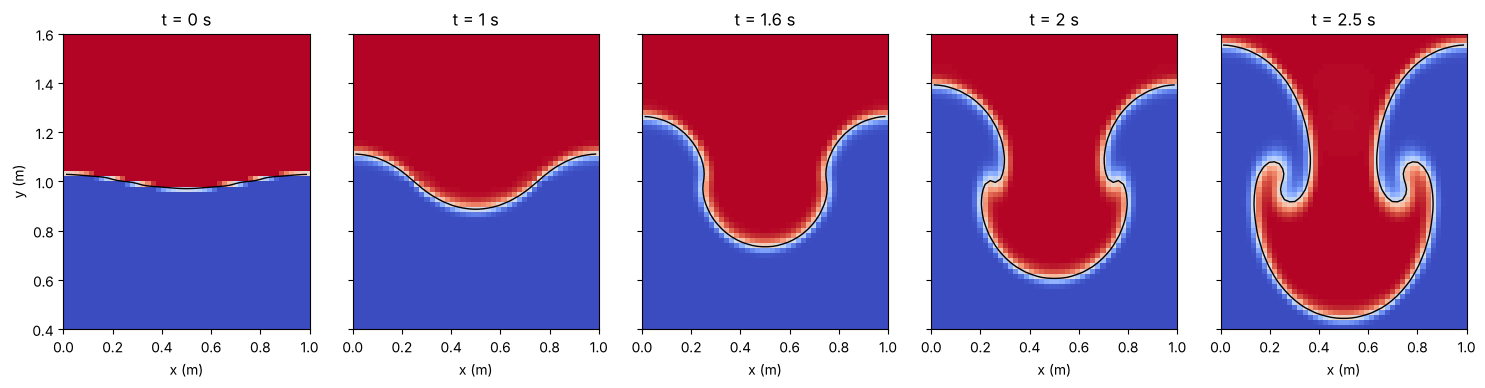

In [ ]:
fig, ax = plt.subplots(1, len(snaps), figsize=(15, 6.5), sharey=True)
for a_, (ts, F) in zip(ax, sorted(snaps.items())):
    a_.pcolormesh(xc, yc, F.T, cmap='coolwarm', vmin=0, vmax=1, shading='auto')
    a_.contour(xc, yc, F.T, levels=[0.5], colors='k', linewidths=1)
    a_.set(title=f't = {ts:g} s', xlabel='x (m)', aspect='equal', ylim=(0.4, 1.6))
ax[0].set_ylabel('y (m)')
plt.tight_layout(); plt.show()

## 6. Growth of the perturbation and comparison with linear theory

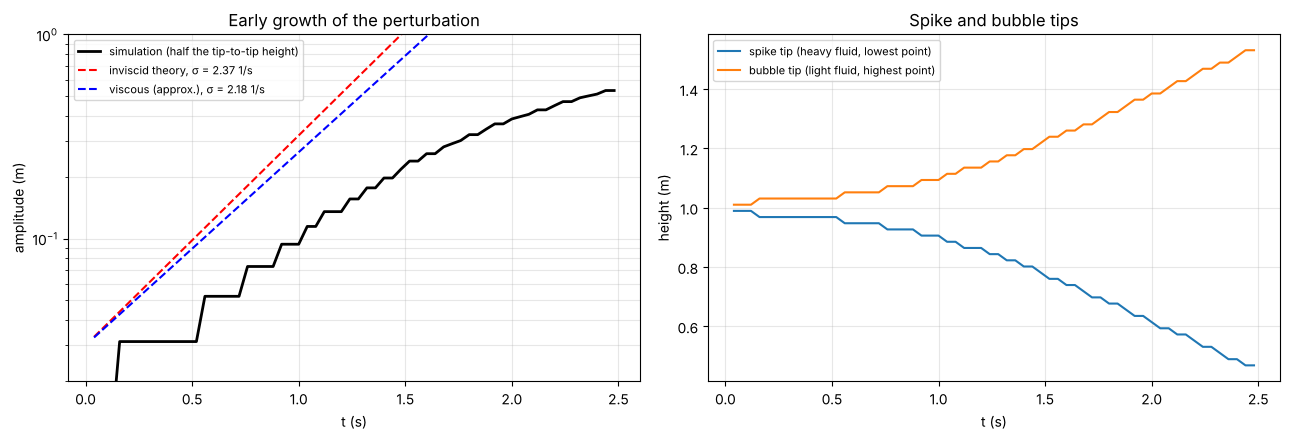

Measured growth rate (0.3 < t < 1.0 s): 1.94 1/s;  inviscid theory 2.37;  viscous approx. 2.18


In [ ]:
t_h = hist[:, 0]
amp = 0.5*(hist[:, 2] - hist[:, 1])
sig_inv = np.sqrt(A_t*g*k)
sig_visc = np.sqrt(A_t*g*k + (nu*k**2)**2) - nu*k**2
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].semilogy(t_h, amp, 'k-', lw=2, label='simulation (half the tip-to-tip height)')
ax[0].semilogy(t_h, amp0*np.exp(sig_inv*t_h), 'r--', label=f'inviscid theory, σ = {sig_inv:.2f} 1/s')
ax[0].semilogy(t_h, amp0*np.exp(sig_visc*t_h), 'b--', label=f'viscous (approx.), σ = {sig_visc:.2f} 1/s')
ax[0].set(xlabel='t (s)', ylabel='amplitude (m)', title='Early growth of the perturbation', ylim=(0.02, 1)); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, which='both')
ax[1].plot(t_h, hist[:, 1], label='spike tip (heavy fluid, lowest point)'); ax[1].plot(t_h, hist[:, 2], label='bubble tip (light fluid, highest point)')
ax[1].set(xlabel='t (s)', ylabel='height (m)', title='Spike and bubble tips'); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# fitted growth rate over the linear stage
mask = (t_h > 0.3) & (t_h < 1.0)
sig_fit = np.polyfit(t_h[mask], np.log(amp[mask]), 1)[0]
print(f"Measured growth rate (0.3 < t < 1.0 s): {sig_fit:.2f} 1/s;  inviscid theory {sig_inv:.2f};  viscous approx. {sig_visc:.2f}")

## 7. Quality checks

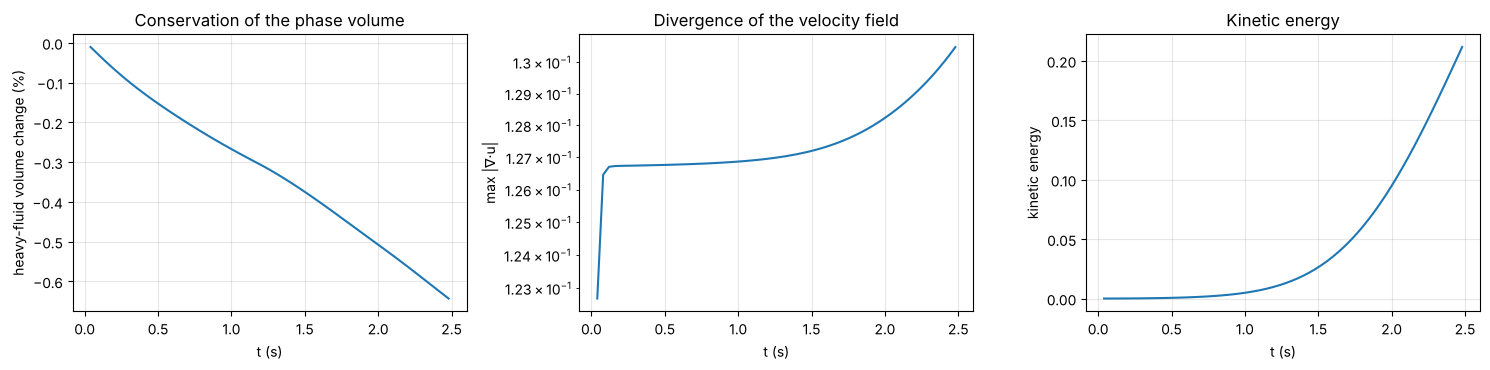

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(hist[:, 0], hist[:, 4]*100); ax[0].set(xlabel='t (s)', ylabel='heavy-fluid volume change (%)', title='Conservation of the phase volume')
ax[1].semilogy(hist[:, 0], hist[:, 3]); ax[1].set(xlabel='t (s)', ylabel='max |∇·u|', title='Divergence of the velocity field')
ax[2].plot(hist[:, 0], hist[:, 5]); ax[2].set(xlabel='t (s)', ylabel='kinetic energy', title='Kinetic energy')
for a_ in ax: a_.grid(alpha=0.3)
plt.tight_layout(); plt.show()